In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp1IXI236-Guys-0817-MPRAGESEN_-s254_-0301-00003-000001-01.nii
/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp2IXI260-HH-1805-MADisoTFE1_-s3T170_-0301-00003-000001-01.nii
/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp1IXI398-Guys-0952-MPRAGESEN_-s412_-0401-00004-000001-01.nii
/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp2IXI224-Guys-0823-MPRAGESEN_-s255_-0301-00003-000001-01.nii
/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp1IXI534-Guys-1062-MPRAGESEN_-s427_-0301-00003-000001-01.nii
/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp1IXI531-Guys-1057-MPRAGESEN_-s427_-0301-00003-000001-01.nii
/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp1IXI476-IOP-1140-SAGFSPGR_-sIXI47_-0003-00001-000001-01.nii
/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i/mwp2IXI159-HH-1549-IXIMADisoTFE12_-s3T145_-030

In [12]:
# ============================================================
# STEP A — PREPROCESS CHENG DATASET
# ============================================================
import os
import h5py
import cv2
import numpy as np
from tqdm import tqdm

CHENG_DIR = "/kaggle/input/datasets/msvlsankar2910/brain-tumor/Dataset/brainTumorDataPublic_1-766"
WORK_DIR = "/kaggle/working"
IMG_SIZE = 224

mat_files = sorted(
    [f for f in os.listdir(CHENG_DIR) if f.endswith('.mat')],
    key=lambda x: int(x.split('.')[0])
)
print(f"Found {len(mat_files)} Cheng .mat files\n")


def load_cheng_mat(path):
    with h5py.File(path, 'r') as f:
        cj = f['cjdata']
        image = np.array(cj['image'], dtype=np.float32)
        label = int(np.array(cj['label']).squeeze())
    return image, label


def preprocess_image(img, size=224):
    vmin, vmax = np.percentile(img, [1, 99])
    img = np.clip((img - vmin) / (vmax - vmin + 1e-8), 0, 1)
    img_u8 = (img * 255).astype(np.uint8)
    img_resized = cv2.resize(img_u8, (size, size), interpolation=cv2.INTER_AREA)
    return np.stack([img_resized] * 3, axis=-1)


X_cheng = np.zeros((len(mat_files), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
y_cheng = np.zeros((len(mat_files),), dtype=np.int64)

for i, fname in enumerate(tqdm(mat_files, desc="Preprocessing Cheng")):
    img, label = load_cheng_mat(os.path.join(CHENG_DIR, fname))
    X_cheng[i] = preprocess_image(img, IMG_SIZE)
    y_cheng[i] = label

LABEL_MAP = {1: 'meningioma', 2: 'glioma', 3: 'pituitary'}
print(f"\nProcessed {len(mat_files)} Cheng files")
print(f"\nClass distribution:")
for lbl in sorted(np.unique(y_cheng)):
    cnt = int((y_cheng == lbl).sum())
    print(f"  {lbl} ({LABEL_MAP[lbl]:12s}): {cnt:5d}  ({cnt/len(y_cheng)*100:.1f}%)")

np.save(f"{WORK_DIR}/X_cheng.npy", X_cheng)
np.save(f"{WORK_DIR}/y_cheng.npy", y_cheng)
print(f"\nSaved: X_cheng.npy ({X_cheng.nbytes/1e6:.1f} MB), y_cheng.npy")

Found 3064 Cheng .mat files



Preprocessing Cheng: 100%|██████████| 3064/3064 [02:43<00:00, 18.75it/s]



Processed 3064 Cheng files

Class distribution:
  1 (meningioma  ):   708  (23.1%)
  2 (glioma      ):  1426  (46.5%)
  3 (pituitary   ):   930  (30.4%)

Saved: X_cheng.npy (461.2 MB), y_cheng.npy


In [13]:
# ============================================================
# STEP B — EXTRACT 2D SLICES FROM IXI (no-tumor class)
# ============================================================
import os
import nibabel as nib
import cv2
import numpy as np
from tqdm import tqdm

IXI_DIR_1 = "/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mr_IXI_480i"
IXI_DIR_2 = "/kaggle/input/datasets/msvlsankar2910/brain-tumor-2/mri_IXI_480_2"
WORK_DIR  = "/kaggle/working"
IMG_SIZE  = 224

# Gather all .nii files
nii_files = []
for folder in [IXI_DIR_1, IXI_DIR_2]:
    if os.path.exists(folder):
        for f in os.listdir(folder):
            if f.endswith('.nii') or f.endswith('.nii.gz'):
                nii_files.append(os.path.join(folder, f))

print(f"Found {len(nii_files)} IXI .nii files\n")

# Extract slices
all_slices = []

for nii_path in tqdm(nii_files, desc="Extracting IXI"):
    try:
        nii = nib.load(nii_path)
        volume = nii.get_fdata().astype(np.float32)

        # Normalize
        vmin, vmax = float(volume.min()), float(volume.max())
        if vmax - vmin < 1e-6:
            continue
        volume = (volume - vmin) / (vmax - vmin)

        # Middle 50% of axial slices (skip empty top/bottom)
        n_slices = volume.shape[2]
        z_start = int(n_slices * 0.25)
        z_end   = int(n_slices * 0.75)
        z_list  = np.linspace(z_start, z_end, 10).astype(int)

        for z in z_list:
            slice_2d = volume[:, :, z]
            # Skip slices with too few brain pixels
            if (slice_2d > 0.1).sum() < 500:
                continue

            slice_uint8 = (slice_2d * 255).astype(np.uint8)
            slice_resized = cv2.resize(slice_uint8, (IMG_SIZE, IMG_SIZE),
                                       interpolation=cv2.INTER_AREA)
            slice_3ch = np.stack([slice_resized] * 3, axis=-1)
            all_slices.append(slice_3ch)
    except Exception:
        continue

all_slices = np.array(all_slices, dtype=np.uint8)
print(f"\nExtracted {all_slices.shape[0]} slices")
print(f"Shape: {all_slices.shape}")
print(f"Memory: {all_slices.nbytes / 1e6:.1f} MB")

# Sample ~1500 for balance with Cheng tumor classes
N_SAMPLES = min(1500, len(all_slices))
np.random.seed(42)
idx = np.random.choice(len(all_slices), N_SAMPLES, replace=False)
notumor_slices = all_slices[idx]

# Label = 4 for "no tumor"
notumor_labels = np.full(N_SAMPLES, 4, dtype=np.int64)

print(f"\nSampled {N_SAMPLES} no-tumor slices")
print(f"Final shape: {notumor_slices.shape}")

# Save
np.save(f"{WORK_DIR}/X_notumor.npy", notumor_slices)
np.save(f"{WORK_DIR}/y_notumor.npy", notumor_labels)
print(f"\nSaved: X_notumor.npy ({notumor_slices.nbytes/1e6:.1f} MB)")
print(f"       y_notumor.npy (all labels = 4)")

Found 1569 IXI .nii files



Extracting IXI: 100%|██████████| 1569/1569 [06:50<00:00,  3.82it/s]



Extracted 15326 slices
Shape: (15326, 224, 224, 3)
Memory: 2307.0 MB

Sampled 1500 no-tumor slices
Final shape: (1500, 224, 224, 3)

Saved: X_notumor.npy (225.8 MB)
       y_notumor.npy (all labels = 4)


In [14]:
# ============================================================
# STEP C — COMBINE CHENG + IXI INTO 4-CLASS DATASET
# ============================================================
import numpy as np

WORK_DIR = "/kaggle/working"

# Load both
X_cheng   = np.load(f"{WORK_DIR}/X_cheng.npy")
y_cheng   = np.load(f"{WORK_DIR}/y_cheng.npy")
X_notumor = np.load(f"{WORK_DIR}/X_notumor.npy")
y_notumor = np.load(f"{WORK_DIR}/y_notumor.npy")

print(f"Cheng loaded: shape={X_cheng.shape}, labels={np.unique(y_cheng)}")
print(f"IXI loaded  : shape={X_notumor.shape}, labels={np.unique(y_notumor)}")

# Combine
X_all = np.concatenate([X_cheng, X_notumor], axis=0)
y_all = np.concatenate([y_cheng, y_notumor], axis=0)

# Remap labels 1,2,3,4 -> 0,1,2,3 for softmax
y_all = y_all - 1

print(f"\nCombined dataset:")
print(f"  X_all shape: {X_all.shape}")
print(f"  y_all shape: {y_all.shape}")
print(f"  y_all classes: {np.unique(y_all)}")

# Class distribution
CLASS_NAMES = ['meningioma', 'glioma', 'pituitary', 'no_tumor']
print(f"\nClass distribution:")
for idx, name in enumerate(CLASS_NAMES):
    cnt = int((y_all == idx).sum())
    print(f"  {idx} ({name:12s}): {cnt:5d}  ({cnt/len(y_all)*100:.1f}%)")

# Save combined
np.save(f"{WORK_DIR}/X_all.npy", X_all)
np.save(f"{WORK_DIR}/y_all.npy", y_all)
print(f"\nSaved: X_all.npy ({X_all.nbytes/1e6:.1f} MB)")
print(f"       y_all.npy ({y_all.nbytes/1e6:.2f} MB)")

Cheng loaded: shape=(3064, 224, 224, 3), labels=[1 2 3]
IXI loaded  : shape=(1500, 224, 224, 3), labels=[4]

Combined dataset:
  X_all shape: (4564, 224, 224, 3)
  y_all shape: (4564,)
  y_all classes: [0 1 2 3]

Class distribution:
  0 (meningioma  ):   708  (15.5%)
  1 (glioma      ):  1426  (31.2%)
  2 (pituitary   ):   930  (20.4%)
  3 (no_tumor    ):  1500  (32.9%)

Saved: X_all.npy (687.0 MB)
       y_all.npy (0.04 MB)


In [15]:
# ============================================================
# STEP D — SPLIT + PIPELINES + CLASS WEIGHTS
# ============================================================
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers

WORK_DIR    = "/kaggle/working"
NUM_CLASSES = 4
CLASS_NAMES = ['meningioma', 'glioma', 'pituitary', 'no_tumor']
BATCH_SIZE  = 32

# ---- Load ----
X_all = np.load(f"{WORK_DIR}/X_all.npy")
y_all = np.load(f"{WORK_DIR}/y_all.npy")

# ---- One-hot ----
y_cat = to_categorical(y_all, NUM_CLASSES)

# ---- Stratified 70/15/15 split ----
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_cat, test_size=0.30, stratify=y_all, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp.argmax(1), random_state=42
)

print(f"Train: {X_train.shape[0]}")
print(f"Val  : {X_val.shape[0]}")
print(f"Test : {X_test.shape[0]}")

print(f"\nClass distribution per split:")
for name, yy in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    counts = yy.sum(axis=0).astype(int)
    print(f"  {name:5s}: men={counts[0]:4d}  gli={counts[1]:4d}  pit={counts[2]:4d}  noT={counts[3]:4d}")

# ---- Augmentation ----
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.10),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.10),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")

# ---- tf.data pipelines ----
def make_dataset(X, y, batch_size, shuffle=False, augment=False):
    y = tf.cast(y, tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=42)
    ds = ds.batch(batch_size)
    if augment:
        ds = ds.map(
            lambda x, y: (data_augmentation(tf.cast(x, tf.float32), training=True), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    else:
        ds = ds.map(
            lambda x, y: (tf.cast(x, tf.float32), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, BATCH_SIZE, shuffle=True,  augment=True)
val_ds   = make_dataset(X_val,   y_val,   BATCH_SIZE, shuffle=False, augment=False)
test_ds  = make_dataset(X_test,  y_test,  BATCH_SIZE, shuffle=False, augment=False)

print(f"\nTrain batches: {len(train_ds)}")
print(f"Val batches  : {len(val_ds)}")
print(f"Test batches : {len(test_ds)}")

for xb, yb in train_ds.take(1):
    print(f"\nx dtype: {xb.dtype}, shape: {xb.shape}")
    print(f"y dtype: {yb.dtype}, shape: {yb.shape}")
    print(f"x range: [{xb.numpy().min():.0f}, {xb.numpy().max():.0f}]")

# ---- Class weights ----
y_train_int = y_train.argmax(axis=1)
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train_int)
class_weights = {i: float(w) for i, w in enumerate(cw)}

print(f"\nClass weights:")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i} ({name:12s}): {class_weights[i]:.4f}")

weights_list = [float(class_weights[i]) for i in range(NUM_CLASSES)]
sample_weight_vec = tf.constant(weights_list, dtype=tf.float32)
print(f"\nsample_weight_vec: {sample_weight_vec.numpy()}")

Train: 3194
Val  : 685
Test : 685

Class distribution per split:
  Train: men= 495  gli= 998  pit= 651  noT=1050
  Val  : men= 106  gli= 214  pit= 140  noT= 225
  Test : men= 107  gli= 214  pit= 139  noT= 225


I0000 00:00:1791399451.684846      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791399451.688286      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Train batches: 100
Val batches  : 22
Test batches : 22

x dtype: <dtype: 'float32'>, shape: (32, 224, 224, 3)
y dtype: <dtype: 'float32'>, shape: (32, 4)
x range: [0, 255]

Class weights:
  0 (meningioma  ): 1.6131
  1 (glioma      ): 0.8001
  2 (pituitary   ): 1.2266
  3 (no_tumor    ): 0.7605

sample_weight_vec: [1.6131313 0.8001002 1.2265745 0.7604762]


In [16]:
# ============================================================
# STEP E — BUILD BAYESIAN DW-CNN (4-CLASS)
# ============================================================
import tensorflow as tf
from tensorflow.keras import layers


# ---- DW-Sep Block ----
class BayesianDepthwiseSeparableConv(layers.Layer):
    def __init__(self, filters, kernel_size=3, strides=1,
                 dropout_rate=0.0, name="bayes_dw_sep", **kwargs):
        super().__init__(name=name, **kwargs)
        self.filters      = filters
        self.kernel_size  = kernel_size
        self.strides      = strides
        self.dropout_rate = dropout_rate

        self.depthwise = layers.DepthwiseConv2D(
            kernel_size=kernel_size, strides=strides, padding='same',
            use_bias=False,
            depthwise_regularizer=tf.keras.regularizers.l2(1e-5),
        )
        self.pointwise = layers.Conv2D(
            filters=filters, kernel_size=1, strides=1, padding='same',
            use_bias=False,
            kernel_regularizer=tf.keras.regularizers.l2(1e-5),
        )
        self.bn  = layers.BatchNormalization(momentum=0.99)
        self.act = layers.ReLU()

    def call(self, inputs, training=None):
        x = self.depthwise(inputs)
        x = self.pointwise(x)
        x = self.bn(x, training=training)
        x = self.act(x)
        return x


# ---- Bayesian Encoder Head (auxiliary, produces mu/logvar for KL) ----
class BayesianEncoderHead(layers.Layer):
    def __init__(self, latent_dim=128, name="bayes_encoder", **kwargs):
        super().__init__(name=name, **kwargs)
        self.latent_dim = latent_dim
        self.gap        = layers.GlobalAveragePooling2D()
        self.fc_mu      = layers.Dense(
            latent_dim, kernel_initializer='zeros', bias_initializer='zeros',
            kernel_regularizer=tf.keras.regularizers.l2(1e-4), name="enc_mu")
        self.fc_logvar  = layers.Dense(
            latent_dim, kernel_initializer='zeros', bias_initializer='zeros',
            kernel_regularizer=tf.keras.regularizers.l2(1e-4), name="enc_logvar")

    def call(self, inputs, training=None):
        h = self.gap(inputs)
        mu = self.fc_mu(h)
        logvar = tf.clip_by_value(self.fc_logvar(h), -3.0, 3.0)
        # Feature map unchanged; only mu/logvar used for KL loss
        return inputs, mu, logvar


# ---- Full Model Builder (4-class) ----
def build_bayesian_dw_cnn(input_shape=(224, 224, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape, name="input_image")

    x = layers.Conv2D(32, 3, strides=2, padding='same',
                      use_bias=False, name="stem_conv")(inputs)
    x = layers.BatchNormalization(momentum=0.99, name="stem_bn")(x)
    x = layers.ReLU(name="stem_relu")(x)

    x = BayesianDepthwiseSeparableConv(32,   3, 1, name="dw_sep_1")(x)
    x = BayesianDepthwiseSeparableConv(64,   3, 2, name="dw_sep_2")(x)
    x = BayesianDepthwiseSeparableConv(128,  3, 2, name="dw_sep_3")(x)
    x = BayesianDepthwiseSeparableConv(256,  3, 2, name="dw_sep_4")(x)
    x = BayesianDepthwiseSeparableConv(512,  3, 2, name="dw_sep_5")(x)
    x = BayesianDepthwiseSeparableConv(1024, 3, 1, name="dw_sep_6")(x)

    x, mu, logvar = BayesianEncoderHead(latent_dim=128, name="bayes_encoder")(x)

    x = layers.GlobalAveragePooling2D(name="gap")(x)

    x = layers.Dense(1024, activation='relu', name="fc1")(x)
    x = layers.Dropout(0.5, name="drop1")(x)
    x = layers.Dense(512, activation='relu', name="fc2")(x)
    x = layers.Dropout(0.5, name="drop2")(x)
    x = layers.Dense(256, activation='relu', name="fc3")(x)
    x = layers.Dropout(0.5, name="drop3")(x)
    outputs = layers.Dense(num_classes, activation='softmax',
                           dtype='float32', name="output")(x)

    full_model  = tf.keras.Model(inputs, [outputs, mu, logvar],
                                 name="Bayesian_DW_CNN")
    infer_model = tf.keras.Model(inputs, outputs, name="inference_model")
    return full_model, infer_model


full_model, infer_model = build_bayesian_dw_cnn((224, 224, 3), NUM_CLASSES)
full_model.summary()
print(f"\nTotal params: {full_model.count_params():,}")

Model: "Bayesian_DW_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_relu (ReLU)                │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_sep_1                        │ (None, 112, 112, 32)   │         1,440 │
│ (BayesianDepthwiseSeparableCon… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_sep_2                        │ (None, 56, 56, 64)     │         2,592 │
│ (BayesianDepthwiseSeparableCon… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_sep_3                        │ (None, 28, 28, 128)    │         9,280 │
│ (BayesianDepthwiseSeparableCon… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_sep_4                        │ (None, 14, 14, 256)    │        34,944 │
│ (BayesianDepthwiseSeparableCon… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_sep_5                        │ (None, 7, 7, 512)      │       135,424 │
│ (BayesianDepthwiseSeparableCon… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_sep_6                        │ (None, 7, 7, 1024)     │       532,992 │
│ (BayesianDepthwiseSeparableCon… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bayes_encoder                   │ [(None, 7, 7, 1024),   │       262,400 │
│ (BayesianEncoderHead)           │ (None, 128), (None,    │               │
│                                 │ 128)]                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc3 (Dense)                     │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,686,820 (10.25 MB)

 Trainable params: 2,682,724 (10.23 MB)

 Non-trainable params: 4,096 (16.00 KB)


Total params: 2,686,820


In [17]:
# ============================================================
# SANITY CHECK
# ============================================================
for xb, yb in train_ds.take(1):
    preds, mu, logvar = full_model(xb, training=True)
    print(f"Input:  {xb.shape}")
    print(f"Preds:  {preds.shape}   (expect (32, 4))")
    print(f"Mu:     {mu.shape}      (expect (32, 128))")
    print(f"Logvar: {logvar.shape}  (expect (32, 128))")
    print(f"Softmax sums: {preds.numpy().sum(axis=1)[:5]}")
    break

Input:  (32, 224, 224, 3)
Preds:  (32, 4)   (expect (32, 4))
Mu:     (32, 128)      (expect (32, 128))
Logvar: (32, 128)  (expect (32, 128))
Softmax sums: [1.         1.         0.99999994 1.         1.        ]


In [18]:
# ============================================================
# STEP F1 — TRAINING CONFIG
# ============================================================
import tensorflow as tf
import numpy as np
from tensorflow.keras import optimizers
import time

EPOCHS         = 100
LEARNING_RATE  = 5e-4
BETA_KL        = 1e-5
PATIENCE       = 20
CKPT_PATH      = "/kaggle/working/best_bayes_dw_cnn_4class.weights.h5"

ce_loss = tf.keras.losses.CategoricalCrossentropy(
    from_logits=False,
    label_smoothing=0.05,
)

optimizer = optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0)

weights_list = [float(class_weights[i]) for i in range(NUM_CLASSES)]
sample_weight_vec = tf.constant(weights_list, dtype=tf.float32)
print("Sample weight vector:", sample_weight_vec.numpy(), sample_weight_vec.dtype)

train_acc = tf.keras.metrics.CategoricalAccuracy(name="train_acc")
val_acc   = tf.keras.metrics.CategoricalAccuracy(name="val_acc")

history = {
    "loss": [], "nll": [], "kl": [],
    "train_acc": [],
    "val_loss": [], "val_nll": [], "val_kl": [], "val_acc": [],
}

print("Step F1 done")

Sample weight vector: [1.6131313 0.8001002 1.2265745 0.7604762] <dtype: 'float32'>
Step F1 done


In [19]:
# ============================================================
# STEP F2 — TRAIN / VAL STEPS
# ============================================================
@tf.function
def train_step(x, y):
    y = tf.cast(y, tf.float32)
    x = tf.cast(x, tf.float32)

    with tf.GradientTape() as tape:
        preds, mu, logvar = full_model(x, training=True)

        sample_w = tf.reduce_sum(y * sample_weight_vec, axis=-1)
        nll = ce_loss(y, preds)
        nll = tf.reduce_mean(nll * sample_w)

        kl_enc = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=-1)
        )

        reg_losses = tf.add_n(full_model.losses) if full_model.losses else 0.0
        total_loss = nll + BETA_KL * kl_enc + reg_losses

    grads = tape.gradient(total_loss, full_model.trainable_variables)
    optimizer.apply_gradients(zip(grads, full_model.trainable_variables))
    train_acc.update_state(y, preds)
    return total_loss, nll, kl_enc


@tf.function
def val_step(x, y):
    y = tf.cast(y, tf.float32)
    x = tf.cast(x, tf.float32)

    preds, mu, logvar = full_model(x, training=False)

    sample_w = tf.reduce_sum(y * sample_weight_vec, axis=-1)
    nll = ce_loss(y, preds)
    nll = tf.reduce_mean(nll * sample_w)

    kl_enc = -0.5 * tf.reduce_mean(
        tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=-1)
    )
    total_loss = nll + BETA_KL * kl_enc
    val_acc.update_state(y, preds)
    return total_loss, nll, kl_enc

print("Step F2 done — train_step and val_step defined")

Step F2 done — train_step and val_step defined


In [21]:
# ============================================================
# STEP F3 — SMOKE TEST
# ============================================================
for xb, yb in train_ds.take(1):
    L, nll, kl = train_step(xb, yb)
    print(f"train_step OK: loss={float(L):.4f}  nll={float(nll):.4f}  kl={float(kl):.4f}")
    break

for xb, yb in val_ds.take(1):
    L, nll, kl = val_step(xb, yb)
    print(f"val_step OK  : loss={float(L):.4f}  nll={float(nll):.4f}  kl={float(kl):.4f}")
    break


train_step OK: loss=1.4518  nll=1.4381  kl=-0.0000
val_step OK  : loss=1.4094  nll=1.4094  kl=-0.0000


In [22]:
# ============================================================
# STEP F4 — TRAINING LOOP (100 epochs)
# ============================================================
print(f"Training for up to {EPOCHS} epochs  (early stop patience={PATIENCE})\n")
print(f"{'Epoch':>5} | {'loss':>8} | {'nll':>8} | {'kl':>8} | "
      f"{'tr_acc':>7} | {'v_loss':>8} | {'v_acc':>7} | {'time':>6}")
print("-" * 85)

best_val_acc = 0.0
wait = 0
start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # ---- Train ----
    train_acc.reset_state()
    tr_loss_sum, tr_nll_sum, tr_kl_sum, n_tr = 0.0, 0.0, 0.0, 0
    for xb, yb in train_ds:
        L, nll, kl = train_step(xb, yb)
        tr_loss_sum += float(L)
        tr_nll_sum  += float(nll)
        tr_kl_sum   += float(kl)
        n_tr += 1

    tr_loss = tr_loss_sum / max(n_tr, 1)
    tr_nll  = tr_nll_sum  / max(n_tr, 1)
    tr_kl   = tr_kl_sum   / max(n_tr, 1)
    tr_acc  = float(train_acc.result())

    # ---- Validate ----
    val_acc.reset_state()
    v_loss_sum, v_nll_sum, v_kl_sum, n_v = 0.0, 0.0, 0.0, 0
    for xb, yb in val_ds:
        L, nll, kl = val_step(xb, yb)
        v_loss_sum += float(L)
        v_nll_sum  += float(nll)
        v_kl_sum   += float(kl)
        n_v += 1

    v_loss = v_loss_sum / max(n_v, 1)
    v_nll  = v_nll_sum  / max(n_v, 1)
    v_kl   = v_kl_sum   / max(n_v, 1)
    v_acc  = float(val_acc.result())

    epoch_time = time.time() - epoch_start

    # ---- Log ----
    print(f"{epoch+1:>5} | {tr_loss:>8.4f} | {tr_nll:>8.4f} | {tr_kl:>8.4f} | "
          f"{tr_acc:>7.4f} | {v_loss:>8.4f} | {v_acc:>7.4f} | {epoch_time:>5.1f}s")

    history["loss"].append(tr_loss)
    history["nll"].append(tr_nll)
    history["kl"].append(tr_kl)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(v_loss)
    history["val_nll"].append(v_nll)
    history["val_kl"].append(v_kl)
    history["val_acc"].append(v_acc)

    # ---- Checkpoint ----
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        wait = 0
        infer_model.save_weights(CKPT_PATH)
        print(f"        >> new best val_acc={v_acc:.4f}  saved")
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch+1} "
                  f"(no improvement for {PATIENCE} epochs)")
            break

print("\n" + "=" * 70)
print(f"Training done in {(time.time()-start)/60:.1f} min")
print(f"Best val_acc : {best_val_acc:.4f}")
print(f"Weights saved: {CKPT_PATH}")
print("=" * 70)

Training for up to 100 epochs  (early stop patience=20)

Epoch |     loss |      nll |       kl |  tr_acc |   v_loss |   v_acc |   time
-------------------------------------------------------------------------------------
    1 |   1.0118 |   0.9981 |   0.0000 |  0.5833 |   1.3794 |  0.3285 |  25.1s
        >> new best val_acc=0.3285  saved
    2 |   0.8058 |   0.7922 |   0.0000 |  0.7063 |   1.4228 |  0.3285 |  20.6s
    3 |   0.7420 |   0.7285 |   0.0000 |  0.7439 |   1.4825 |  0.3285 |  21.1s
    4 |   0.7185 |   0.7050 |   0.0000 |  0.7533 |   1.6366 |  0.3285 |  21.2s
    5 |   0.6794 |   0.6660 |   0.0000 |  0.7805 |   1.7269 |  0.3285 |  21.3s
    6 |   0.6531 |   0.6397 |   0.0000 |  0.7893 |   1.0102 |  0.5314 |  21.3s
        >> new best val_acc=0.5314  saved
    7 |   0.6309 |   0.6175 |   0.0000 |  0.8062 |   0.6948 |  0.7328 |  21.2s
        >> new best val_acc=0.7328  saved
    8 |   0.5973 |   0.5839 |   0.0000 |  0.8228 |   1.2885 |  0.6161 |  21.2s
    9 |   0.5708 |  

In [23]:
# ============================================================
# STEP G1 — LOAD BEST WEIGHTS AND EVALUATE ON TEST SET
# ============================================================
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

# Load best weights
infer_model.load_weights("/kaggle/working/best_bayes_dw_cnn_4class.weights.h5")
print("Loaded best weights from epoch 81")

# Predict on test set
y_pred_probs = infer_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

# Test accuracy
test_acc = accuracy_score(y_true, y_pred)
print(f"\nTest Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

# Weighted metrics
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print(f"\nWeighted Metrics:")
print(f"  Precision: {prec:.4f}")
print(f"  Recall   : {rec:.4f}")
print(f"  F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

Loaded best weights from epoch 81


I0000 00:00:1791401848.851401     188 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



Test Accuracy: 0.9358 (93.58%)

Weighted Metrics:
  Precision: 0.9405
  Recall   : 0.9358
  F1-score : 0.9322

Classification Report:
              precision    recall  f1-score   support

  meningioma     0.9589    0.6542    0.7778       107
      glioma     0.9324    0.9673    0.9495       214
   pituitary     0.8424    1.0000    0.9145       139
    no_tumor     1.0000    1.0000    1.0000       225

    accuracy                         0.9358       685
   macro avg     0.9334    0.9054    0.9104       685
weighted avg     0.9405    0.9358    0.9322       685



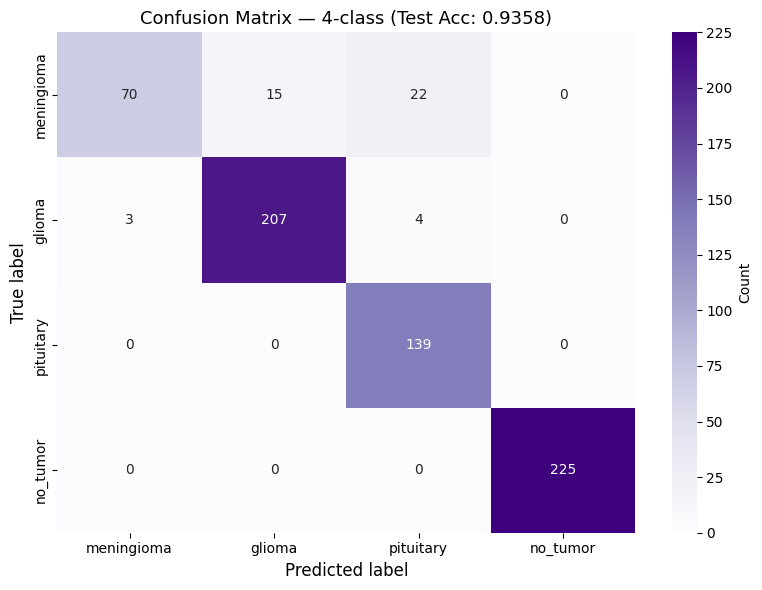

In [24]:
# ============================================================
# STEP G2 — CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Count'})
plt.xlabel("Predicted label", fontsize=12)
plt.ylabel("True label", fontsize=12)
plt.title(f"Confusion Matrix — 4-class (Test Acc: {test_acc:.4f})", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix_4class.png", dpi=150)
plt.show()

In [25]:
# ============================================================
# FINAL SUMMARY VS PAPER
# ============================================================
best_epoch = int(np.argmax(history["val_acc"]))
train_at_best = history["train_acc"][best_epoch]
val_at_best = history["val_acc"][best_epoch]

print("=" * 70)
print("FINAL RESULTS — 4-class Bayesian DW-CNN on Cheng + IXI")
print("=" * 70)
print(f"Best epoch: {best_epoch + 1} / 100")
print(f"Training accuracy @ best: {train_at_best:.4f}")
print(f"Validation accuracy (best): {val_at_best:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Precision (weighted): {prec:.4f}")
print(f"Recall (weighted): {rec:.4f}")
print(f"F1-score (weighted): {f1:.4f}")
print()
print("-" * 70)
print("COMPARISON WITH PAPER (4-class)")
print("-" * 70)
print(f"{'Metric':20s} | {'Paper':>10s} | {'Ours':>10s} | {'Delta':>10s}")
print("-" * 70)
print(f"{'Training acc':20s} | {'99.03%':>10s} | {train_at_best*100:>9.2f}% | {train_at_best*100 - 99.03:>+9.2f}%")
print(f"{'Validation acc':20s} | {'94.32%':>10s} | {val_at_best*100:>9.2f}% | {val_at_best*100 - 94.32:>+9.2f}%")
print(f"{'Test acc':20s} | {'(N/A)':>10s} | {test_acc*100:>9.2f}% |")
print(f"{'Precision':20s} | {'0.95':>10s} | {prec:>10.4f} | {prec - 0.95:>+10.4f}")
print(f"{'Recall':20s} | {'0.94':>10s} | {rec:>10.4f} | {rec - 0.94:>+10.4f}")
print(f"{'F1-score':20s} | {'0.94':>10s} | {f1:>10.4f} | {f1 - 0.94:>+10.4f}")
print("=" * 70)

FINAL RESULTS — 4-class Bayesian DW-CNN on Cheng + IXI
Best epoch: 81 / 100
Training accuracy @ best: 0.9446
Validation accuracy (best): 0.9328
Test accuracy: 0.9358
Precision (weighted): 0.9405
Recall (weighted): 0.9358
F1-score (weighted): 0.9322

----------------------------------------------------------------------
COMPARISON WITH PAPER (4-class)
----------------------------------------------------------------------
Metric               |      Paper |       Ours |      Delta
----------------------------------------------------------------------
Training acc         |     99.03% |     94.46% |     -4.57%
Validation acc       |     94.32% |     93.28% |     -1.04%
Test acc             |      (N/A) |     93.58% |
Precision            |       0.95 |     0.9405 |    -0.0095
Recall               |       0.94 |     0.9358 |    -0.0042
F1-score             |       0.94 |     0.9322 |    -0.0078
